# Sequential (greedy) per-sample input sensitivity analysis

Greedy conditional leave-one-out (LOCO) sensitivity: at each step, the input
token whose NaN-masking maximizes the prediction change vs the full-input
baseline is selected per sample, kept masked, and the process repeats
(like PCA's n_components, but for input tokens).

- Deterministic predictions: error = MSE between baseline and masked prediction.
- Probabilistic (mu, raw_sigma) heads: error = 2-Wasserstein distance between
  the Gaussian predictions (accounts for variance), or KL divergence.
- Output: one row per test sample, columns sens_k / err_k / err_pct_k.

Memory note (optimized backend): candidates are evaluated in parallel via
batch expansion, so peak GPU memory scales with
batch_size * chunk_size * L^2 * n_heads (attention scores dominate).
chunk_size=None derives a safe value from max_chunk_memory_mb, and on CUDA
OOM the chunk is automatically halved and retried. Reduce
max_chunk_memory_mb (or set a small chunk_size) if your GPU is tight.

References: Lei et al. 2018 (LOCO); Covert et al. 2020 (SAGE);
Sturmfels et al. 2021 (removal-based explanations); Borgonovo 2007
(moment-independent sensitivity).

In [1]:
from os.path import dirname, abspath, join
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from proT.proj_specific.GSA.leave_one_out import get_config_and_best_checkpoint
from proT.proj_specific.GSA.sequential_sensitivity import get_sequential_sensitivity_df

ROOT_DIR = dirname(abspath(''))
datadir_path = join(ROOT_DIR, 'data/input')
experiment_path = join(ROOT_DIR, 'experiments/baseline_optuna/euler/baseline_proT_dyconex_sum_50908169')
output_path = join(ROOT_DIR, 'experiments/evaluations/sequential_sensitivity/df_seq_sens.csv')

config, checkpoint_path = get_config_and_best_checkpoint(experiment_path)

S6 Mamba backend: mamba-pytorch (pure PyTorch fallback)


In [2]:
# Run the analysis (optimized backend: single model load, batch expansion).
# values_to_mask=None -> all variable ids present in the split (excl. padding 0).
# error_metric='auto' -> W2 for Gaussian heads, MSE for deterministic ones.
df_seq = get_sequential_sensitivity_df(
    config=config,
    datadir_path=datadir_path,
    checkpoint_path=checkpoint_path,
    n_most_sensitive=10,
    values_to_mask=None,
    split='test',
    error_metric='auto',
    backend='optimized',
    chunk_size=None,  # auto from max_chunk_memory_mb; halved+retried on OOM
    max_chunk_memory_mb=2048,  # per-chunk GPU memory budget (reduce if tight)
    output_path=output_path,
)
df_seq.head()

Seed set to 42


Error metric: mse (probabilistic=False)
SEQUENTIAL SENSITIVITY ANALYSIS (backend=optimized, K=10)
Loading model from checkpoint...


c:\Users\ScipioneFrancesco\Documents\Projects\proT\myenv\Lib\site-packages\torch\__init__.py:1617: UserWarning: Please use the new API settings to control TF32 behavior, such as torch.backends.cudnn.conv.fp32_precision = 'tf32' or torch.backends.cuda.matmul.fp32_precision = 'ieee'. Old settings, e.g, torch.backends.cuda.matmul.allow_tf32 = True, torch.backends.cudnn.allow_tf32 = True, allowTF32CuDNN() and allowTF32CuBLAS() will be deprecated after Pytorch 2.9. Please see https://pytorch.org/docs/main/notes/cuda.html#tensorfloat-32-tf32-on-ampere-and-later-devices (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:85.)
  _C._set_float32_matmul_precision(precision)


Loading pre-split data.
Train input shape:  (1526, 1023, 12)
Train target shape:  (1526, 400, 9)
Test input shape:  (394, 1023, 12)
Test target shape:  (394, 400, 9)
Loading pre-split data.
Train input shape:  (1526, 1023, 12)
Train target shape:  (1526, 400, 9)
Test input shape:  (394, 1023, 12)
Test target shape:  (394, 400, 9)
[optimized] Pass 1: baseline predictions (no masking)...


Baseline: 100%|██████████| 8/8 [00:00<00:00,  8.89it/s]


...

Step 9: 100%|██████████| 8/8 [05:18<00:00, 39.76s/it]


[optimized] Step 10/10...


Step 10: 100%|██████████| 8/8 [05:17<00:00, 39.70s/it]


Results saved to c:\Users\ScipioneFrancesco\Documents\Projects\proT\experiments\evaluations\sequential_sensitivity\df_seq_sens.csv

Sample results:
   sample_idx  sens_1         err_1  err_pct_1  sens_2     err_2  err_pct_2  \
0           0      10  6.497853e-05   0.071553     209  0.000189   0.207651   
1           1     269  9.100718e-07   0.001019     277  0.000004   0.004133   
2           2     298  3.374323e-06   0.003158     269  0.000008   0.007758   
3           3     287  3.159984e-05   0.038549     295  0.000119   0.144680   
4           4      10  5.299127e-03   2.753526      42  0.013010   6.760163   

   sens_3     err_3  err_pct_3  ...  err_pct_7  sens_8     err_8  err_pct_8  \
0      71  0.000594   0.654473  ...   1.180230     225  0.001166   1.284271   
1     305  0.000008   0.008645  ...   0.025924     273  0.000028   0.031147   
2     277  0.000016   0.014708  ...   0.041349     305  0.000051   0.047950   
3     331  0.000215   0.261957  ...   1.040722     311  0.000

,sample_idx,sens_1,err_1,err_pct_1,sens_2,err_2,err_pct_2,sens_3,err_3,err_pct_3,...,err_pct_7,sens_8,err_8,err_pct_8,sens_9,err_9,err_pct_9,sens_10,err_10,err_pct_10
0,0,10,6.497853e-05,0.071553,209,0.000189,0.207651,71,0.000594,0.654473,...,1.180230,225,0.001166,1.284271,98,0.001255,1.382372,186,0.001309,1.440932
1,1,269,9.100718e-07,0.001019,277,0.000004,0.004133,305,0.000008,0.008645,...,0.025924,273,0.000028,0.031147,309,0.000033,0.036755,293,0.000038,0.043088
2,2,298,3.374323e-06,0.003158,269,0.000008,0.007758,277,0.000016,0.014708,...,0.041349,305,0.000051,0.047950,8,0.000059,0.055382,293,0.000068,0.063710
3,3,287,3.159984e-05,0.038549,295,0.000119,0.144680,331,0.000215,0.261957,...,1.040722,311,0.000880,1.074034,299,0.000908,1.108097,337,0.000931,1.135592
4,4,10,5.299127e-03,2.753526,42,0.013010,6.760163,156,0.015201,7.898824,...,11.294974,95,0.021866,11.361789,96,0.021988,11.425335,33,0.022095,11.480817


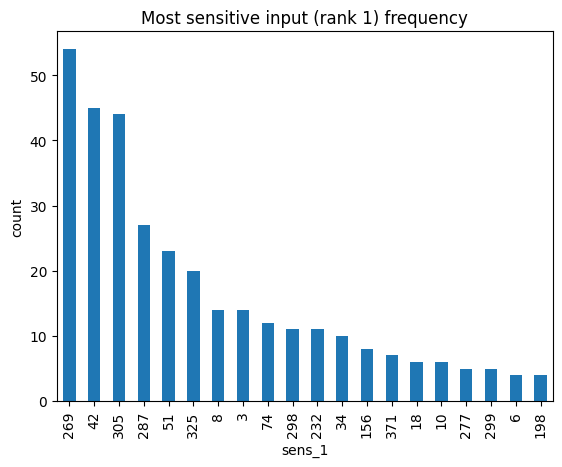

In [3]:
# Most frequently selected 1st-most-sensitive variable across test samples
df_seq['sens_1'].value_counts().head(20).plot(kind='bar')
plt.ylabel('count'); plt.title('Most sensitive input (rank 1) frequency')
plt.show()

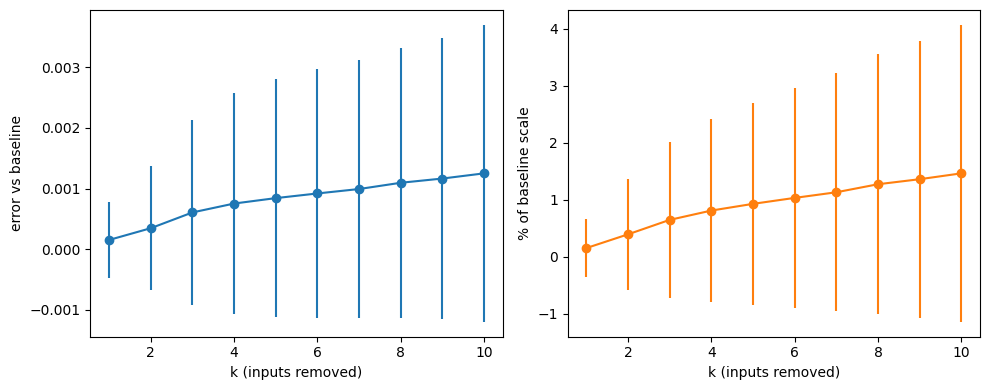

In [4]:
# Mean +/- std of the error (and % of baseline) as a function of k
err_cols = [c for c in df_seq.columns if c.startswith('err_') and not c.startswith('err_pct')]
pct_cols = [c for c in df_seq.columns if c.startswith('err_pct_')]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].errorbar(range(1, len(err_cols) + 1), df_seq[err_cols].mean(),
               yerr=df_seq[err_cols].std(), marker='o')
ax[0].set_xlabel('k (inputs removed)'); ax[0].set_ylabel('error vs baseline')
ax[1].errorbar(range(1, len(pct_cols) + 1), df_seq[pct_cols].mean(),
               yerr=df_seq[pct_cols].std(), marker='o', color='tab:orange')
ax[1].set_xlabel('k (inputs removed)'); ax[1].set_ylabel('% of baseline scale')
fig.tight_layout()
plt.show()